# Ride-time prior from drive time (Google or OpenRouteService)

Model: ride $R = \kappa \cdot T_{\text{drive}}(o, d, t) \cdot e^{\eta}$ (+ optional fixed overhead). $\kappa$ = shared-ride factor, calibrated so EBP-like trips (avg 11.43 mi) average EBP's 48.9-min ride; $\eta \sim \mathcal{N}(0, s^2)$ with $s$ from NYC actual/scheduled ride time plus an assumed extra term.

**Drive-time provider (picked automatically):**
1. `GOOGLE_MAPS_KEY` set → Google Routes API, traffic-aware, future departures. First run ≈ 900 elements (within Google's monthly free allowance; set a budget alert).
2. else `ORS_API_KEY` set → OpenRouteService, free (2,000 directions / 500 matrix requests per day), real roads but **no traffic**: same drive time all day. First run = 2 requests.
3. else → rough offline fallback so the notebook runs; numbers not meaningful.

Results are cached in `drive_cache.json` (per provider).

### 1. Imports & constants

In [26]:
import os, json, hashlib, urllib.request
from datetime import date, datetime, timedelta
from zoneinfo import ZoneInfo
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, optimize

from dotenv import load_dotenv
load_dotenv()  # reads .env from the current working directory and its parents

TZ = ZoneInfo("America/Los_Angeles")
GOOGLE_KEY = os.environ.get("GOOGLE_MAPS_KEY")          # Google Routes API (traffic-aware, future departures)
ORS_KEY = os.environ.get("ORS_API_KEY")                  # OpenRouteService (free, no traffic) if no Google key
CACHE_PATH = "drive_cache.json"                          # Google results are cached here (saves money)

# East Bay Paratransit, Jul '25–Apr '26 (EBPAC packet, July 7, 2026)
EBP_AVG_RIDE_MIN = 48.9
EBP_AVG_TRIP_MI = 11.43

S_RHO = 0.33     # PASTE from ride_time.ipynb (pooled spread of NYC actual/scheduled ride time)
S_EXTRA = 0.15   # ASSUMPTION: extra spread because we don't know the van's manifest in advance
S_RIDE = np.sqrt(S_RHO**2 + S_EXTRA**2)
OVERHEAD_MIN = 0.0   # ASSUMPTION: fixed minutes per ride (boarding, securement). 0 -> pure factor model

BLUE, ORANGE, GRAY, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#a3a29c", "#0b0b0b", "#52514e", "#e6e5e0"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 11})
PROVIDER = "google" if GOOGLE_KEY else "ors" if ORS_KEY else "offline"
print({"google": "Using Google Routes API (traffic-aware)",
       "ors": "Using OpenRouteService (free, typical road speeds, NO traffic -> same drive time all day)",
       "offline": "No key found -> rough offline fallback (numbers not meaningful)"}[PROVIDER])

Using Google Routes API (traffic-aware)


### 2. Drive times: Google Routes API (traffic-aware, future departures), cached; rough fallback offline

In [27]:
def _cache():
    try:
        return json.load(open(CACHE_PATH))
    except (FileNotFoundError, json.JSONDecodeError):
        return {}

_CACHE = _cache()

def _key(o, d, t_iso):
    return hashlib.md5(json.dumps([round(o[0], 5), round(o[1], 5), round(d[0], 5),
                                   round(d[1], 5), t_iso]).encode()).hexdigest()

def haversine_mi(o, d):
    lat1, lon1, lat2, lon2 = map(np.radians, (o[0], o[1], d[0], d[1]))
    a = np.sin((lat2 - lat1) / 2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2)**2
    return 3958.8 * 2 * np.arcsin(np.sqrt(a))

def _fallback(o, d, t_iso):
    """ROUGH offline stand-in: straight-line x 1.3 road factor, speed dips at rush hour. Not for real use."""
    miles = 1.3 * haversine_mi(o, d)
    h = datetime.fromisoformat(t_iso).hour + datetime.fromisoformat(t_iso).minute / 60
    rush = np.exp(-((h - 8.0) / 1.2)**2) + np.exp(-((h - 17.0) / 1.5)**2)
    mph = 28 - 10 * rush - 6 * np.exp(-miles / 4)            # short trips = slower streets
    return 60 * miles / mph, miles

def _google_matrix(origins, dests, t_iso):
    body = {"origins": [{"waypoint": {"location": {"latLng": {"latitude": o[0], "longitude": o[1]}}}} for o in origins],
            "destinations": [{"waypoint": {"location": {"latLng": {"latitude": d[0], "longitude": d[1]}}}} for d in dests],
            "travelMode": "DRIVE", "routingPreference": "TRAFFIC_AWARE", "departureTime": t_iso}
    req = urllib.request.Request(
        "https://routes.googleapis.com/distanceMatrix/v2:computeRouteMatrix", data=json.dumps(body).encode(),
        headers={"Content-Type": "application/json", "X-Goog-Api-Key": GOOGLE_KEY,
                 "X-Goog-FieldMask": "originIndex,destinationIndex,duration,distanceMeters,condition"})
    return json.load(urllib.request.urlopen(req))

def _ors_matrix(origins, dests):
    """OpenRouteService matrix: durations (min) and distances (mi) for all origin x destination pairs."""
    locs = [[o[1], o[0]] for o in origins] + [[d[1], d[0]] for d in dests]      # ORS wants [lng, lat]
    body = {"locations": locs, "sources": list(range(len(origins))),
            "destinations": list(range(len(origins), len(locs))),
            "metrics": ["duration", "distance"], "units": "mi"}
    req = urllib.request.Request(
        "https://api.openrouteservice.org/v2/matrix/driving-car", data=json.dumps(body).encode(),
        headers={"Content-Type": "application/json", "Authorization": ORS_KEY})
    res = json.load(urllib.request.urlopen(req))
    to_arr = lambda m: np.array([[np.nan if v is None else v for v in row] for row in m], float)
    return to_arr(res["durations"]) / 60, to_arr(res["distances"])

def drive_matrix(origins, dests, t_iso):
    """Drive minutes and miles for every origin x destination at departure t_iso.
    Providers bill/limit per element or request, so we only ever request full matrices we actually use."""
    t_key = t_iso if PROVIDER == "google" else "static"      # ORS/offline have no traffic -> time-independent
    O, D = len(origins), len(dests)
    mins, miles = np.full((O, D), np.nan), np.full((O, D), np.nan)
    missing = False
    for i, o in enumerate(origins):
        for j, d in enumerate(dests):
            k = _key(o, d, t_key) + PROVIDER
            if k in _CACHE:
                mins[i, j], miles[i, j] = _CACHE[k]
            elif PROVIDER == "offline":
                mins[i, j], miles[i, j] = _fallback(o, d, t_iso)
            else:
                missing = True
    if missing and PROVIDER == "google":
        assert O * D <= 625, "Google allows at most 625 elements per traffic-aware matrix request"
        for el in _google_matrix(origins, dests, t_iso):
            if el.get("condition") != "ROUTE_EXISTS":
                continue
            i, j = el.get("originIndex", 0), el.get("destinationIndex", 0)
            mins[i, j] = float(el["duration"].rstrip("s")) / 60
            miles[i, j] = el.get("distanceMeters", 0) / 1609.34
    elif missing and PROVIDER == "ors":
        assert O + D <= 3500, "ORS allows at most 3,500 locations per matrix request"
        mins, miles = _ors_matrix(origins, dests)
    if missing:
        for i, o in enumerate(origins):
            for j, d in enumerate(dests):
                if not np.isnan(mins[i, j]):
                    _CACHE[_key(o, d, t_key) + PROVIDER] = [mins[i, j], miles[i, j]]
        json.dump(_CACHE, open(CACHE_PATH, "w"))
    return mins, miles

def next_weekday_iso(weekday, hour, minute=0):
    """Next occurrence (future) of weekday (0=Mon) at local hour:minute, ISO with the correct UTC offset."""
    today = datetime.now(TZ).date()
    days = (weekday - today.weekday()) % 7 or 7
    dt = datetime.combine(today + timedelta(days=days), datetime.min.time()).replace(
        hour=hour, minute=minute, tzinfo=TZ)
    return dt.isoformat()

### 3. Sample plausible EBP trips (homes near transit -> clinics/BART/etc.)

In [28]:
# Anchors: BART stations across EBP's area (approximate coordinates); trips start/end near them.
ANCHORS = {
    "Richmond": (37.9369, -122.3533), "El Cerrito del Norte": (37.9252, -122.3170),
    "North Berkeley": (37.8740, -122.2834), "Downtown Berkeley": (37.8701, -122.2681),
    "Ashby": (37.8529, -122.2700), "Rockridge": (37.8445, -122.2514), "MacArthur": (37.8290, -122.2671),
    "19th St Oakland": (37.8080, -122.2689), "Lake Merritt": (37.7975, -122.2654),
    "Fruitvale": (37.7748, -122.2241), "Coliseum": (37.7537, -122.1969), "San Leandro": (37.7219, -122.1609),
    "Bay Fair": (37.6969, -122.1265), "Castro Valley": (37.6907, -122.0758), "Hayward": (37.6699, -122.0870),
    "South Hayward": (37.6345, -122.0572), "Union City": (37.5908, -122.0174), "Fremont": (37.5574, -121.9764),
}
rng = np.random.default_rng(42)
names = list(ANCHORS)

def jitter(p, km=1.2):                                         # EBP serves 3/4 mi around routes -> ~1 km spread
    dlat, dlon = rng.normal(0, km / 111, 2) / np.array([1, np.cos(np.radians(p[0]))])
    return (p[0] + dlat, p[1] + dlon)

# Trip ends near random anchors. Every origin x destination pair is used (12 x 10 = 120 trips),
# so each Google request returns only elements we need. Trip lengths are matched to EBP in cell 5.
ORIGINS = [jitter(ANCHORS[n]) for n in rng.choice(names, 12)]
DESTS = [jitter(ANCHORS[n]) for n in rng.choice(names, 10)]
print(f"{len(ORIGINS)} origins x {len(DESTS)} destinations = {len(ORIGINS) * len(DESTS)} trips")

12 origins x 10 destinations = 120 trips


### 4. Query drive times across a weekday (cached; 7 requests x 120 elements on first run)

In [29]:
HOURS = [7, 9, 11, 13, 15, 17, 19]
DAY = 3                                                        # Thursday
rows = []
for h in HOURS:
    mins, miles = drive_matrix(ORIGINS, DESTS, next_weekday_iso(DAY, h))   # one request per hour (120 elements)
    for i in range(len(ORIGINS)):
        for j in range(len(DESTS)):
            rows.append(dict(pair=i * len(DESTS) + j, hour=h, drive_min=mins[i, j], miles=miles[i, j]))
drv = pd.DataFrame(rows).dropna()
drv = drv[drv.miles > 0.5]                                     # drop near-identical start/end points
print(drv.groupby("hour")[["drive_min", "miles"]].mean().round(1))

      drive_min  miles
hour                  
7          27.0   15.5
9          29.0   15.7
11         25.2   15.4
13         26.1   15.4
15         30.1   15.4
17         33.6   15.3
19         23.7   15.4


### 5. Calibrate the shared-ride factor kappa to EBP's 48.9 min average ride

In [30]:
# Reweight sampled trips so their average road distance is exactly EBP's 11.43 mi (exponential tilting)
mi_by_pair = drv.groupby("pair").miles.mean()
def tilt(lam):
    w_ = np.exp(lam * mi_by_pair.to_numpy()); return w_ / w_.sum()
lam = optimize.brentq(lambda l: tilt(l) @ mi_by_pair.to_numpy() - EBP_AVG_TRIP_MI, -2, 2)
pair_w = pd.Series(tilt(lam), index=mi_by_pair.index)
drv["w"] = drv.pair.map(pair_w) / len(HOURS)                   # equal weight per departure hour

mean_drive = np.average(drv.drive_min, weights=drv.w)
KAPPA = (EBP_AVG_RIDE_MIN - OVERHEAD_MIN) / mean_drive          # matches the MEAN ride (see ride_prior_drive)
print(f"weighted mean distance {np.average(drv.miles, weights=drv.w):.2f} mi, "
      f"mean direct drive {mean_drive:.1f} min  ->  kappa = {KAPPA:.2f}")

def ride_prior_drive(drive_min, kappa=KAPPA, s=S_RIDE, overhead=OVERHEAD_MIN):
    """Lognormal ride prior (min). Mean ride = overhead + kappa * drive; median = mean * exp(-s^2/2)."""
    mean = overhead + kappa * np.asarray(drive_min, float)
    return stats.lognorm(s, scale=mean * np.exp(-s**2 / 2))

# Save the calibrated ride prior for other notebooks (booking_advice.ipynb)
json.dump({"KAPPA": float(KAPPA), "S_RIDE": float(S_RIDE), "OVERHEAD_MIN": float(OVERHEAD_MIN),
           "PROVIDER": PROVIDER}, open("ride_params.json", "w"), indent=1)
print("saved ride_params.json")

weighted mean distance 11.43 mi, mean direct drive 22.0 min  ->  kappa = 2.23
saved ride_params.json


### 6. Why drive time beats mileage: same distance, very different drives

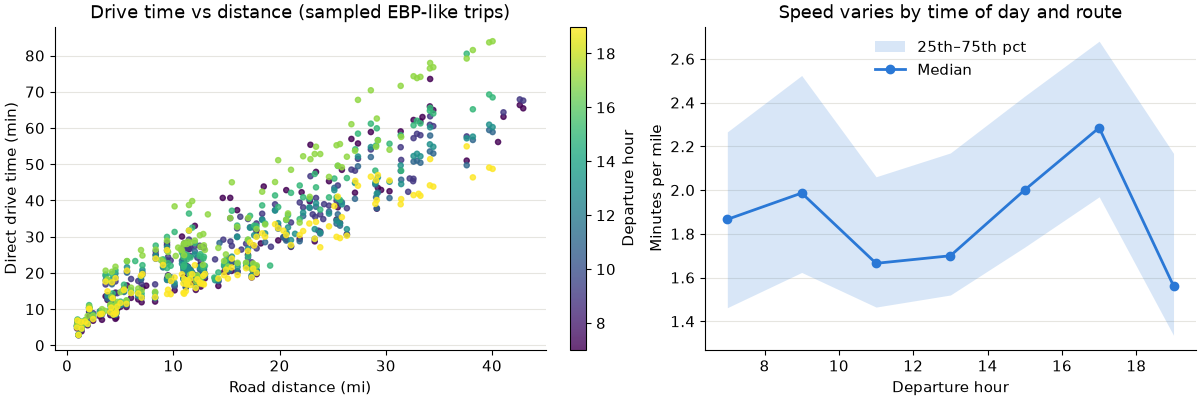

In [31]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
sc = a1.scatter(drv.miles, drv.drive_min, c=drv.hour, cmap="viridis", s=14, alpha=0.8)
fig.colorbar(sc, ax=a1, label="Departure hour")
a1.set(xlabel="Road distance (mi)", ylabel="Direct drive time (min)",
       title="Drive time vs distance (sampled EBP-like trips)")
per_mile = drv.assign(min_per_mi=drv.drive_min / drv.miles).groupby("hour").min_per_mi.describe()
a2.fill_between(per_mile.index, per_mile["25%"], per_mile["75%"], color=BLUE, alpha=0.18, lw=0, label="25th–75th pct")
a2.plot(per_mile.index, per_mile["50%"], "o-", color=BLUE, lw=2, label="Median")
a2.set(xlabel="Departure hour", ylabel="Minutes per mile", title="Speed varies by time of day and route")
a2.legend(frameon=False)
for ax in (a1, a2):
    ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
plt.show()

### 7. One trip across the day: ride prior from drive time (smooth slider; needs ipympl)

In [32]:
# With OpenRouteService the drive time is the same all day (no traffic), so the curve is flat.
%matplotlib widget
import ipywidgets as widgets

TRIP = (jitter(ANCHORS["Hayward"]), (37.7990, -122.2312))      # example: near Hayward BART -> Highland Hospital area (approx.)
t_steps = np.arange(6.0, 21.01, 0.25)                           # every 15 min (61 one-element requests, cached)
trip_drive = np.array([drive_matrix([TRIP[0]], [TRIP[1]], next_weekday_iso(DAY, int(t), int(round(t % 1 * 60))))[0][0, 0]
                       for t in t_steps])
priors = [ride_prior_drive(dm) for dm in trip_drive]
xr = np.linspace(0, max(p.ppf(0.995) for p in priors), 600)
ymax = max(p.pdf(xr).max() for p in priors) * 1.15

def hhmm(t):
    return f"{int(t):02d}:{int(round(t % 1 * 60)):02d}"

plt.ioff()
fig, (b1, b2) = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
fig.canvas.header_visible = False
pdf_line, = b1.plot(xr, np.zeros_like(xr), color=BLUE, lw=2)
drive_line = b1.axvline(0, color=ORANGE, lw=1.5, ls="--", label="Direct drive (Google)")
q_lines = [b1.axvline(0, color=MUTED, lw=1, ls=":") for _ in range(2)]
q_texts = [b1.text(0, 0, "", color=INK, fontsize=9) for _ in range(2)]
b1.set(xlim=(0, xr[-1]), ylim=(0, ymax), xlabel="Ride time (min)", ylabel="Density")
b1.legend(frameon=False, loc="upper right")
title = b1.set_title("", loc="left", color=INK, fontsize=11)

b2.fill_between(t_steps, [p.ppf(0.1) for p in priors], [p.ppf(0.9) for p in priors],
                color=BLUE, alpha=0.18, lw=0, label="Ride 10th–90th pct")
b2.plot(t_steps, [p.median() for p in priors], color=BLUE, lw=2, label="Ride median")
b2.plot(t_steps, trip_drive, color=ORANGE, lw=1.5, ls="--", label="Direct drive")
dot, = b2.plot([], [], "o", ms=10, color=BLUE, mec="white", mew=2)
b2.set(xlim=(t_steps[0], t_steps[-1]), xticks=range(6, 22, 2), xlabel="Departure time",
       ylabel="Minutes", title="This trip across a weekday")
b2.legend(frameon=False, loc="upper left", fontsize=9)
for ax in (b1, b2):
    ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)

def update(t):
    i = int(np.argmin(np.abs(t_steps - t)))
    p, dm = priors[i], trip_drive[i]
    pdf_line.set_ydata(p.pdf(xr))
    drive_line.set_xdata([dm, dm])
    for line, txt, (q_, lab) in zip(q_lines, q_texts, [(0.5, "median"), (0.9, "90th")]):
        v = p.ppf(q_)
        line.set_xdata([v, v]); txt.set_position((v + 1, ymax * 0.85)); txt.set_text(f"{lab}\n{v:.0f} min")
    title.set_text(f"Departing {hhmm(t_steps[i])}: drive {dm:.0f} min, ride mean {p.mean():.0f} min")
    dot.set_data([t_steps[i]], [p.median()])
    fig.canvas.draw_idle()

slider = widgets.FloatSlider(value=13.0, min=t_steps[0], max=t_steps[-1], step=0.25, description="Depart",
                             readout=False, continuous_update=True, layout=widgets.Layout(width="60%"))
label = widgets.Label(hhmm(slider.value))
def on_change(ch):
    update(ch["new"]); label.value = hhmm(t_steps[int(np.argmin(np.abs(t_steps - ch["new"])))])
slider.observe(on_change, names="value")
update(slider.value)
display(widgets.VBox([widgets.HBox([slider, label]), fig.canvas]))

### 8. Putting it together: P(arrive on time) = pickup prior + ride prior (1-D integral)

In [33]:
# Pickup prior from ebp_prior.ipynb: log(L + C) ~ N(pickup_mean, pickup_sd^2). Paste/import those values.
C_EARLY = 5.0

def p_on_time(appt, window_start, drive_min, pickup_mean, pickup_sd, now=None, m=2000):
    """Times in hours. Average of F_ride(D - L) over the (conditional) pickup distribution."""
    D = (appt - window_start) * 60
    tail = 1.0
    if now is not None:
        waited = max((now - window_start) * 60, -C_EARLY + 0.01)
        tail = stats.norm.sf((np.log(waited + C_EARLY) - pickup_mean) / pickup_sd)
    u = (np.arange(m) + 0.5) / m
    L = np.maximum(np.exp(pickup_mean + pickup_sd * stats.norm.isf(u * tail)) - C_EARLY, 0)
    return np.mean(ride_prior_drive(drive_min).cdf(D - L))

# Example: 2:00 appointment, 1:00 window, Google drive at 1:15 for the example trip
dm_115 = trip_drive[np.argmin(np.abs(t_steps - 13.25))]
for ws in (12.5, 12.75, 13.0):
    print(f"window {hhmm(ws)}: P(on time) = {p_on_time(14.0, ws, dm_115, 2.62, 0.588):.2f}")
print("window 13:00, still waiting at 13:20:", round(p_on_time(14.0, 13.0, dm_115, 2.62, 0.588, now=13 + 20/60), 2))

window 12:30: P(on time) = 0.90
window 12:45: P(on time) = 0.77
window 13:00: P(on time) = 0.54
window 13:00, still waiting at 13:20: 0.16
